# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [1]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('data/retailmax.csv')

In [3]:
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df = df.rename(columns={"Spending Score (1-100)" : "SpS"})

In [5]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),SpS
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

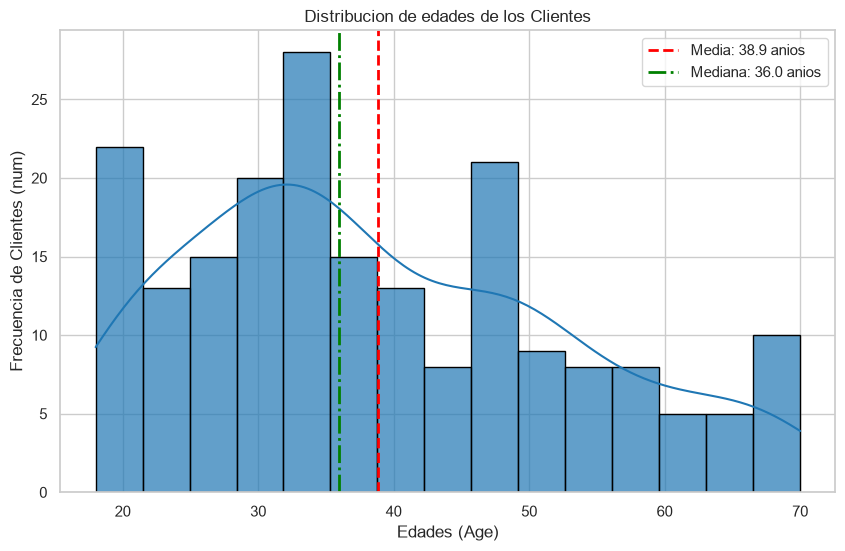

In [6]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=15, kde=True, color='#1f77b4', edgecolor='black', alpha=0.7 )
plt.title("Distribucion de edades de los Clientes", fontsize= 12)
plt.xlabel("Edades (Age)")
plt.ylabel("Frecuencia de Clientes (num)")
plt.axvline(df['Age'].mean(), color = 'red', linestyle = "--", linewidth= 2, label=f'Media: {df["Age"].mean():.1f} anios')
plt.axvline(df['Age'].median(), color = 'green', linestyle = "-.", linewidth= 2, label=f'Mediana: {df["Age"].median():.1f} anios')
plt.legend(fontsize=11)
plt.show()

### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

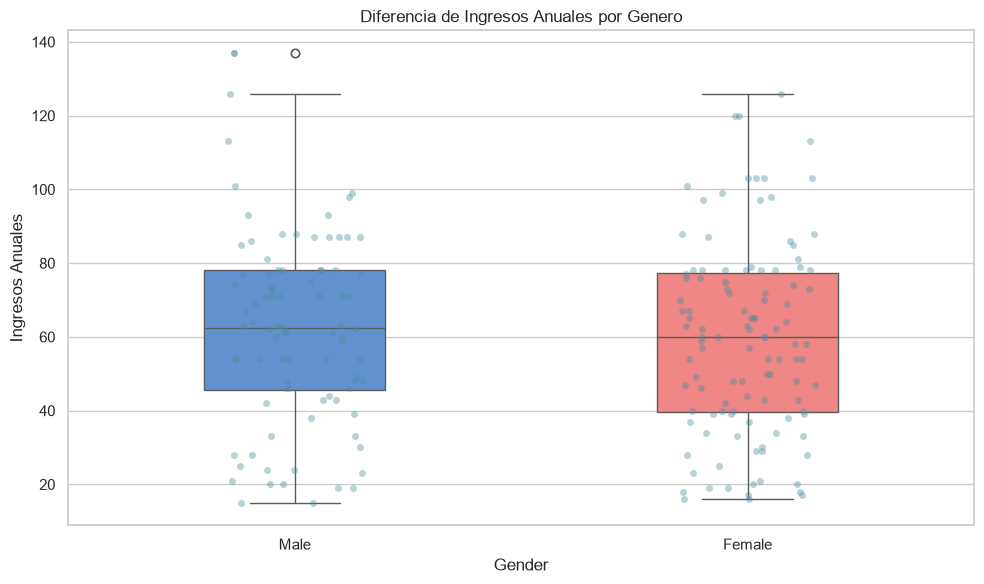

In [7]:
plt.figure(figsize= (10,6))

sns.boxplot(
    data = df,
    x = 'Gender',
    y = 'Annual Income (k$)',
    palette = {'Male': '#4e90e2', 'Female' : '#ff7675'},
    width=0.4,
    showcaps= True,
    meanprops = {"marker": "D", "markerfacecolor": "white", "markededgecolor":"black", "markersize": 8},
)

sns.stripplot(
    data = df,
        x = 'Gender',
        y = 'Annual Income (k$)',
        color = "#4f8c9e",
        alpha = 0.4, 
        jitter = 0.15,
        size = 5
)

plt.title("Diferencia de Ingresos Anuales por Genero")
plt.xlabel("Gender")
plt.ylabel("Ingresos Anuales")

plt.tight_layout()
plt.show()

### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

In [8]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'SpS'], dtype='str')

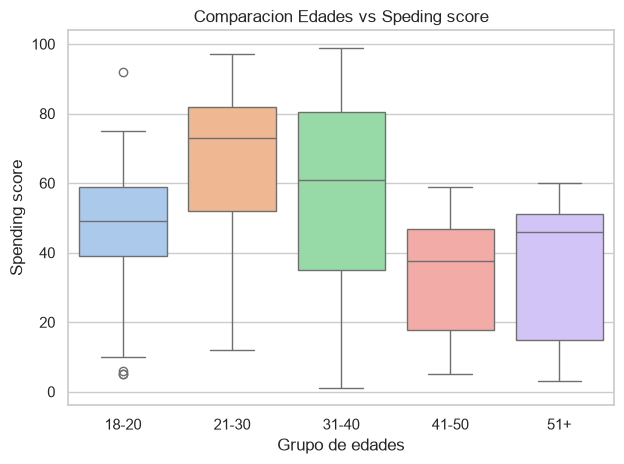

In [9]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 100],
    labels=['18-20', '21-30', '31-40', '41-50', '51+']
)

sns.boxplot(
    data=df,
    x='Age_Group',
    y='SpS',
    palette='pastel'
)

plt.title("Comparacion Edades vs Speding score")
plt.xlabel("Grupo de edades")
plt.ylabel("Spending score")

plt.tight_layout()
plt.show()

### Se puede observar que el grupo de 21 a 30 anios de edad tiene el Spendin Score mas alto y apartir del grupo de los 41 baja drasticamente manteniendose en el mas bajo.

In [10]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),SpS,Age_Group
0,1,Male,19,15,39,18-20
1,2,Male,21,15,81,21-30
2,3,Female,20,16,6,18-20
3,4,Female,23,16,77,21-30
4,5,Female,31,17,40,31-40


# 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

0.009902848094037606


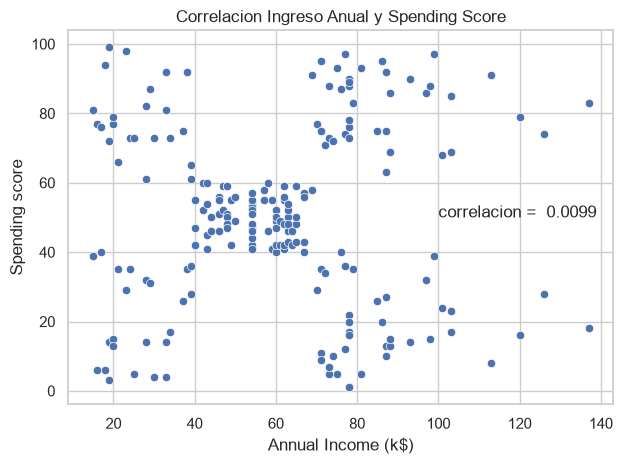

In [11]:
sns.scatterplot(
    data = df,
    x = 'Annual Income (k$)',
    y = 'SpS',
    palette = 'pastel'
)

correlacion = df['Annual Income (k$)'].corr(df['SpS'])
print(correlacion)

plt.title("Correlacion Ingreso Anual y Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending score")
plt.text(
    100, 50,
    f"correlacion =  {correlacion:.4f}", 
    
)

plt.tight_layout()
plt.show()




### Conclusion: Como se muestra en la grafica, no existe una correlacion lineal entre ambos valores, si no que estos se dividen en 5 grupos. 

# 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

In [12]:
df['Annual Income (k$)'].describe()



count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Annual Income (k$), dtype: float64

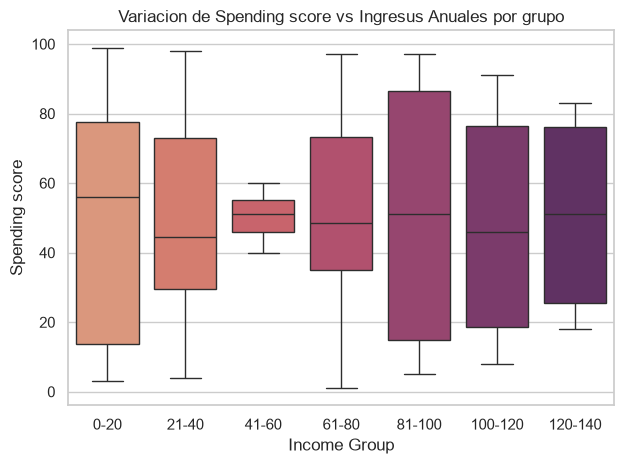

In [13]:
df['Income_Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 20, 40, 60, 80, 100, 120, 140],
    labels=['0-20', '21-40', '41-60', '61-80', '81-100','100-120', '120-140']
)

sns.boxplot(
    data = df,
    x = 'Income_Group',
    y = 'SpS',
    palette = 'flare',
)
plt.title("Variacion de Spending score vs Ingresus Anuales por grupo")
plt.xlabel("Income Group")
plt.ylabel("Spending score")


plt.tight_layout()
plt.show()



### Conclusion: Al agrupoar clientes por ingresu anual, la mediana del Spending score se mantiene en un rango entre aproximadamente 40 y 60 anios en la mayoria de los grupos. 

### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

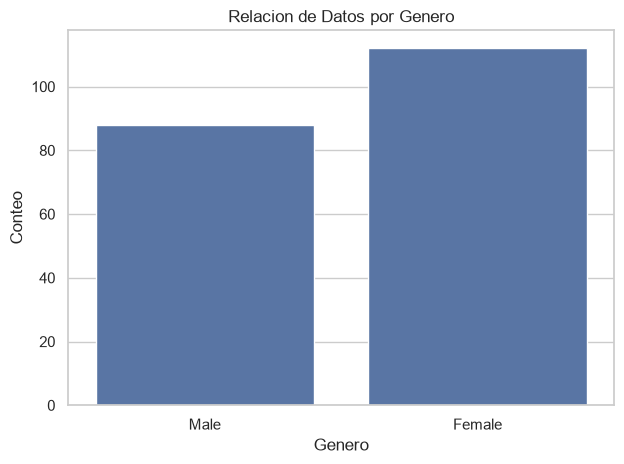

In [14]:
sns.countplot(
    data = df, 
    x = 'Gender'

)

plt.title('Relacion de Datos por Genero')
plt.xlabel('Genero')
plt.ylabel('Conteo')


plt.tight_layout()
plt.show()

# 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

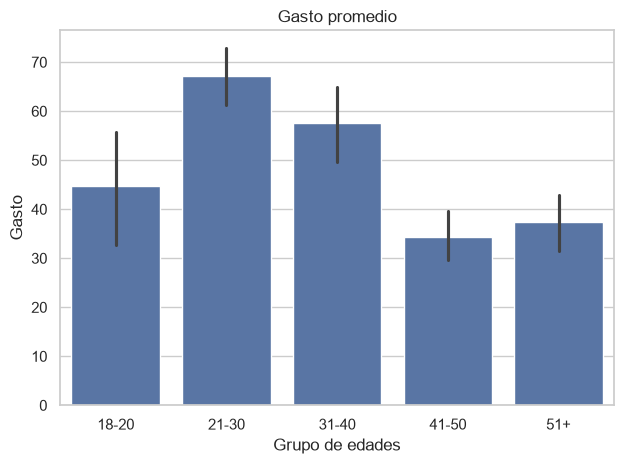

In [20]:
sns.barplot(
    data = df,
    x = 'Age_Group',
    y = 'SpS'
)

plt.title('Gasto promedio')
plt.xlabel('Grupo de edades')
plt.ylabel('Gasto')


plt.tight_layout()
plt.show()

# 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

-0.01239804273606014


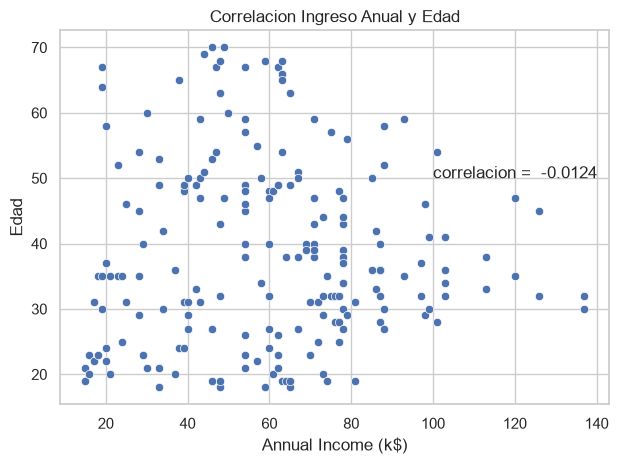

In [24]:
sns.scatterplot(
    data = df,
    x = 'Annual Income (k$)',
    y = 'Age',
    palette = 'pastel'
)

correlacion1 = df['Annual Income (k$)'].corr(df['Age'])
print(correlacion1)

plt.title("Correlacion Ingreso Anual y Edad")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Edad")
plt.text(
    100, 50,
    f"correlacion =  {correlacion1:.4f}", 
    
)

plt.tight_layout()
plt.show()



### Conclusion: Esto nos indica que no existe una relacion lineal entre la edad y el Annual Income (k$) por lo que no me ayudaria a hacer una prediccion.

# 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

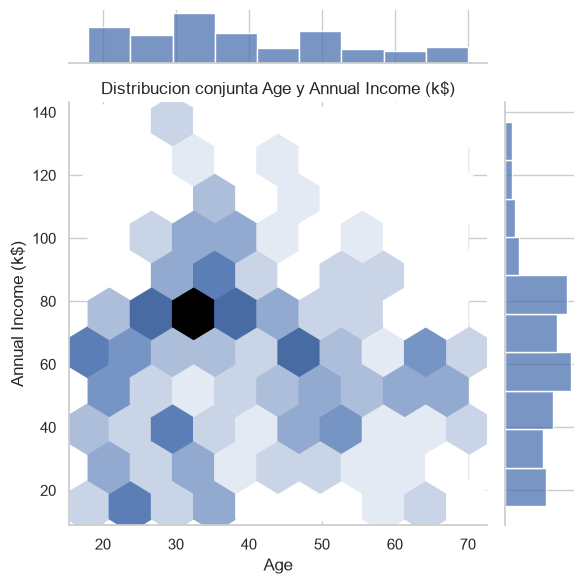

In [29]:
sns.jointplot(kind="hex",
              data = df,
              x = 'Age',
              y = 'Annual Income (k$)'
              )

plt.title("Distribucion conjunta Age y Annual Income (k$)")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")


plt.tight_layout()
plt.show()

### Conclusion: Se puede observar que la mayoria de clientes se encuentran entre los 35 anios de edad y con un Annual Income (k$) de entre 60 y 80.

### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

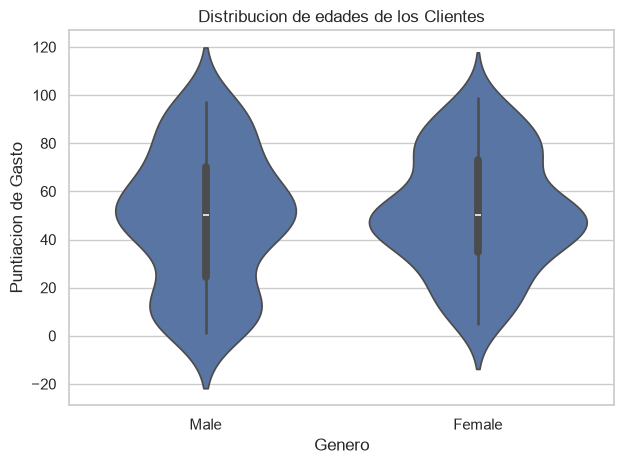

In [37]:
sns.violinplot(
    data = df,
    x = 'Gender',
    y = 'SpS'
)

#plt.title("Grafico Violin para distribucion de Puntuacion de gastos por genero.")
#plt.xlabel("Genero")
#plt.ylabel("Puntuacion de Gasto")


plt.title("Distribucion de edades de los Clientes", fontsize= 12)
plt.xlabel("Genero")
plt.ylabel("Puntiacion de Gasto")


plt.tight_layout()
plt.show()